<a href="https://colab.research.google.com/github/afrineejhilik71-arch/plant-disease-detection/blob/main/Copy_of_02_baseline_comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 — Baseline comparison of pretrained CNNs, per crop


**Protocol (same for every model, so the comparison is fair)**
- Input 224×224, aspect ratio kept (padding), ImageNet weights.
- Fold *k* = test, fold *(k+1) mod 5* = validation, other three folds = training.
- Phase 1: backbone frozen, train only the new head (max 10 epochs).
- Phase 2: fine-tune the whole network with a small learning rate (max 30 epochs).
- Early stopping on validation loss, best weights restored. Class weights for imbalance.
- Augmentation on training images only: flips, small rotation, zoom, contrast.
- Test metrics: accuracy, balanced accuracy, macro precision/recall/F1, weighted F1, Cohen's κ, MCC, parameters, inference time.

**Resumable:** every finished run is saved to Drive immediately. If Colab disconnects, run all cells again and finished runs are skipped.

Runtime: **GPU (T4 or better)**.

## 1. GPU check

In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


## 2. Mount Drive and set up paths

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import json, time, gc
import numpy as np
import pandas as pd

PROJECT = Path('/content/drive/MyDrive/thesis')
DATASET_NAME = 'agri_vision'
ZIP_PATH = PROJECT / 'data/raw/agri_vision.zip'
MANIFEST = PROJECT / 'data/splits' / f'{DATASET_NAME}_manifest.csv'

OUT = PROJECT / 'experiments' / 'baselines'
(OUT / 'preds').mkdir(parents=True, exist_ok=True)
(OUT / 'history').mkdir(parents=True, exist_ok=True)
RESULTS_CSV = OUT / 'results.csv'
print('Results will be saved in', OUT)

Mounted at /content/drive
Results will be saved in /content/drive/MyDrive/thesis/experiments/baselines


## 3. Unzip the images to fast local disk

In [ ]:
UNZIP_DIR = Path('/content/data') / DATASET_NAME
if not UNZIP_DIR.exists():
    UNZIP_DIR.mkdir(parents=True)
    !unzip -q "{ZIP_PATH}" -d "{UNZIP_DIR}"
    for inner in list(UNZIP_DIR.rglob('*.zip')):
        !unzip -q -o "{inner}" -d "{inner.parent}"

ORIG_DIR = [p for p in UNZIP_DIR.rglob('*') if p.is_dir() and 'original' in p.name.lower()][0]
man = pd.read_csv(MANIFEST)
man = man[man.keep].copy()
man['full_path'] = man.rel_path.map(lambda r: str(ORIG_DIR / r))
missing = (~man.full_path.map(lambda p: Path(p).exists())).sum()
print('Originals folder:', ORIG_DIR)
print('Clean images in manifest:', len(man), '| missing on disk:', missing)

Originals folder: /content/data/agri_vision/Agri-Vision4 A Comprehensive Multi-Crop Leaf Disea/Bottle Gourd, Papaya, Tomato, and Zucchini Original Dataset
Clean images in manifest: 3749 | missing on disk: 0


## 4. Libraries, settings and versions

In [ ]:
import tensorflow as tf
import keras
from keras import layers
from PIL import Image, ImageOps
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             precision_score, recall_score, cohen_kappa_score,
                             matthews_corrcoef, confusion_matrix)
from sklearn.utils.class_weight import compute_class_weight

keras.mixed_precision.set_global_policy('mixed_float16')   # ~2x faster on T4/L4/A100

SEED = 42
IMG_SIZE = 224
BATCH = 32
N_FOLDS = 5
HEAD_EPOCHS, HEAD_LR = 10, 1e-3
FT_EPOCHS, FT_LR = 30, 2e-5

versions = {'tensorflow': tf.__version__, 'keras': keras.__version__,
            'gpu': [d.name for d in tf.config.list_physical_devices('GPU')]}
print(versions)
(OUT / 'config.json').write_text(json.dumps({
    **versions, 'seed': SEED, 'img_size': IMG_SIZE, 'batch': BATCH,
    'head_epochs': HEAD_EPOCHS, 'head_lr': HEAD_LR, 'ft_epochs': FT_EPOCHS, 'ft_lr': FT_LR,
    'optimizer': 'AdamW(weight_decay=1e-4)', 'precision': 'mixed_float16',
    'early_stopping': 'val_loss, patience 3 (head) / 5 (fine-tune), restore best',
    'augmentation': 'flip h+v, rotation 0.1, zoom 0.1, contrast 0.1 (train only)'}, indent=2))

{'tensorflow': '2.21.0', 'keras': '3.13.2', 'gpu': ['/physical_device:GPU:0']}


457

## 5. The models
Each entry: how to build the backbone, and the preprocessing it was trained with on ImageNet.
EfficientNetV2, MobileNetV3 and ConvNeXt include their own preprocessing, so they get raw 0–255 pixels.

In [ ]:
A = keras.applications
identity = lambda x: x

MODELS = {
    'VGG16':            (A.VGG16,            A.vgg16.preprocess_input),
    'ResNet50':         (A.ResNet50,         A.resnet50.preprocess_input),
    'DenseNet121':      (A.DenseNet121,      A.densenet.preprocess_input),
    'InceptionV3':      (A.InceptionV3,      A.inception_v3.preprocess_input),
    'Xception':         (A.Xception,         A.xception.preprocess_input),
    'MobileNetV3Large': (A.MobileNetV3Large, identity),
    'EfficientNetV2B0': (A.EfficientNetV2B0, identity),
    'ConvNeXtTiny':     (A.ConvNeXtTiny,     identity),
}

def build_model(name, n_classes):
    ctor, _ = MODELS[name]
    base = ctor(include_top=False, weights='imagenet', input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = base(inp, training=False)          # BatchNorm stays in inference mode, also when fine-tuning
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(n_classes, activation='softmax', dtype='float32')(x)
    return keras.Model(inp, out, name=name), base

## 6. Data loading and training functions

In [ ]:
def load_crop(crop):
    d = man[man.crop == crop].sort_values('rel_path').reset_index(drop=True)
    classes = sorted(d.label.unique())
    y = d.label.map({c: i for i, c in enumerate(classes)}).to_numpy()
    X = np.stack([np.asarray(ImageOps.pad(Image.open(p).convert('RGB'), (IMG_SIZE, IMG_SIZE),
                                          color=(0, 0, 0)), dtype=np.uint8)
                  for p in d.full_path])
    return d, X, y, classes

augment = keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name='augment')

def make_ds(X, y, prep, train):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if train:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH).map(lambda a, b: (tf.cast(a, tf.float32), b), num_parallel_calls=tf.data.AUTOTUNE)
    if train:
        ds = ds.map(lambda a, b: (augment(a, training=True), b), num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(lambda a, b: (prep(a), b), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.AdamW(learning_rate=lr, weight_decay=1e-4),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])

def run_one(crop, name, fold, data):
    d, X, y, classes = data
    folds = d.fold.to_numpy()
    te, va = folds == fold, folds == (fold + 1) % N_FOLDS
    tr = ~(te | va)
    keras.utils.set_random_seed(SEED + fold)
    prep = MODELS[name][1]
    ds_tr = make_ds(X[tr], y[tr], prep, True)
    ds_va = make_ds(X[va], y[va], prep, False)
    ds_te = make_ds(X[te], y[te], prep, False)
    cw = compute_class_weight('balanced', classes=np.arange(len(classes)), y=y[tr])
    cw = dict(enumerate(cw))

    model, base = build_model(name, len(classes))
    t0 = time.perf_counter()
    compile_model(model, HEAD_LR)
    h1 = model.fit(ds_tr, validation_data=ds_va, epochs=HEAD_EPOCHS, class_weight=cw, verbose=0,
                   callbacks=[keras.callbacks.EarlyStopping('val_loss', patience=3, restore_best_weights=True)])
    base.trainable = True
    compile_model(model, FT_LR)
    h2 = model.fit(ds_tr, validation_data=ds_va, epochs=FT_EPOCHS, class_weight=cw, verbose=0,
                   callbacks=[keras.callbacks.EarlyStopping('val_loss', patience=5, restore_best_weights=True),
                              keras.callbacks.ReduceLROnPlateau('val_loss', factor=0.5, patience=2)])
    train_min = (time.perf_counter() - t0) / 60

    model.predict(ds_te.take(1), verbose=0)                       # warm-up
    t1 = time.perf_counter()
    prob = model.predict(ds_te, verbose=0)
    ms_per_img = 1000 * (time.perf_counter() - t1) / te.sum()
    pred, true = prob.argmax(1), y[te]

    hist = pd.concat([pd.DataFrame(h1.history).assign(phase='head'),
                      pd.DataFrame(h2.history).assign(phase='finetune')], ignore_index=True)
    hist.to_csv(OUT / 'history' / f'{crop}_{name}_fold{fold}.csv', index=False)
    pr = pd.DataFrame({'rel_path': d.rel_path[te].values, 'y_true': true, 'y_pred': pred})
    pr[[f'p_{c}' for c in classes]] = prob
    pr.to_csv(OUT / 'preds' / f'{crop}_{name}_fold{fold}.csv', index=False)

    return {
        'crop': crop, 'model': name, 'fold': fold,
        'n_train': int(tr.sum()), 'n_val': int(va.sum()), 'n_test': int(te.sum()),
        'accuracy': accuracy_score(true, pred),
        'balanced_accuracy': balanced_accuracy_score(true, pred),
        'macro_precision': precision_score(true, pred, average='macro', zero_division=0),
        'macro_recall': recall_score(true, pred, average='macro', zero_division=0),
        'macro_f1': f1_score(true, pred, average='macro', zero_division=0),
        'weighted_f1': f1_score(true, pred, average='weighted', zero_division=0),
        'cohen_kappa': cohen_kappa_score(true, pred),
        'mcc': matthews_corrcoef(true, pred),
        'params_M': model.count_params() / 1e6,
        'epochs_head': len(h1.history['loss']), 'epochs_finetune': len(h2.history['loss']),
        'train_minutes': train_min, 'infer_ms_per_img': ms_per_img,
        'classes': '|'.join(classes),
        'confusion_matrix': json.dumps(confusion_matrix(true, pred, labels=range(len(classes))).tolist()),
    }

## 7. Choose what to run
**Start with the pilot:** `FOLDS = [0]` trains every model once per crop (24 runs, about 1.5–3 hours on a T4).
After the pilot, change to `FOLDS = [0, 1, 2, 3, 4]` and run sections 7–8 again: finished runs are skipped.

In [ ]:
CROPS = ['Tomato', 'Papaya', 'Bottle_Gourd']     # smallest crop first
MODEL_NAMES = list(MODELS)                        # all 8 models
FOLDS = [0]                                       # pilot; later [0, 1, 2, 3, 4]

done = set()
if RESULTS_CSV.exists():
    r = pd.read_csv(RESULTS_CSV)
    done = set(zip(r.crop, r.model, r.fold))
todo = [(c, m, f) for c in CROPS for m in MODEL_NAMES for f in FOLDS if (c, m, f) not in done]
print(f'{len(done)} runs already finished, {len(todo)} to do now')

23 runs already finished, 1 to do now


## 8. Training Datasets and Using CNN Models

In [ ]:
current_crop, data = None, None
for i, (crop, name, fold) in enumerate(todo, 1):
    if crop != current_crop:
        data = load_crop(crop); current_crop = crop
        print(f'\nLoaded {crop}: {len(data[2])} images, {len(data[3])} classes')
    try:
        row = run_one(crop, name, fold, data)
    except Exception as e:
        print(f'[{i}/{len(todo)}] {crop:12s} {name:17s} fold {fold}  FAILED: {e}')
        continue
    pd.DataFrame([row]).to_csv(RESULTS_CSV, mode='a', header=not RESULTS_CSV.exists(), index=False)
    print(f"[{i}/{len(todo)}] {crop:12s} {name:17s} fold {fold}  "
          f"acc {row['accuracy']:.3f}  macroF1 {row['macro_f1']:.3f}  ({row['train_minutes']:.1f} min)")
    keras.backend.clear_session(); gc.collect()
print('\nAll requested runs finished.')


Loaded Bottle_Gourd: 1491 images, 7 classes
111650432/111650432 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
[1/1] Bottle_Gourd ConvNeXtTiny      fold 0  acc 0.772  macroF1 0.739  (9.1 min)

All requested runs finished.


## 9. Summary table and Excel file

In [ ]:
r = pd.read_csv(RESULTS_CSV)
metrics = ['accuracy', 'balanced_accuracy', 'macro_f1', 'weighted_f1', 'mcc']
agg = r.groupby(['crop', 'model']).agg(
    folds=('fold', 'nunique'),
    **{f'{m}_mean': (m, 'mean') for m in metrics},
    **{f'{m}_std': (m, 'std') for m in metrics},
    params_M=('params_M', 'first'), infer_ms_per_img=('infer_ms_per_img', 'mean'),
    train_minutes=('train_minutes', 'mean')).reset_index()

def mean_std(m):
    return agg.apply(lambda x: f"{100*x[m+'_mean']:.2f}" + (f" ± {100*x[m+'_std']:.2f}"
                                                         if x.folds > 1 else ''), axis=1)
table = agg[['crop', 'model', 'folds']].copy()
for m in metrics:
    table[m + ' (%)'] = mean_std(m)
table[['params_M', 'infer_ms_per_img']] = agg[['params_M', 'infer_ms_per_img']].round(2)
table = table.loc[agg.sort_values(['crop', 'macro_f1_mean'], ascending=[True, False]).index]

best = agg.loc[agg.groupby('crop').macro_f1_mean.idxmax(), ['crop', 'model', 'macro_f1_mean']]
print('Best model per crop (by macro-F1):')
display(best)
display(table)

with pd.ExcelWriter(OUT / 'baseline_results.xlsx') as xw:
    table.to_excel(xw, sheet_name='summary', index=False)
    agg.to_excel(xw, sheet_name='summary_numeric', index=False)
    r.drop(columns=['confusion_matrix']).to_excel(xw, sheet_name='all_runs', index=False)
    pd.read_json(OUT / 'config.json', typ='series').rename('value').to_frame().to_excel(xw, sheet_name='protocol')
print('Saved', OUT / 'baseline_results.xlsx')

Best model per crop (by macro-F1):


,crop,model,macro_f1_mean
0,Bottle_Gourd,ConvNeXtTiny,0.738518
8,Papaya,ConvNeXtTiny,0.671850
17,Tomato,DenseNet121,0.713176


,crop,model,folds,accuracy (%),balanced_accuracy (%),macro_f1 (%),weighted_f1 (%),mcc (%),params_M,infer_ms_per_img
0,Bottle_Gourd,ConvNeXtTiny,1,77.15,74.20,73.85,77.36,72.80,27.83,30.94
1,Bottle_Gourd,DenseNet121,1,77.48,73.93,71.39,78.11,73.38,7.04,54.84
3,Bottle_Gourd,InceptionV3,1,72.85,67.11,67.02,73.06,67.56,21.82,74.72
5,Bottle_Gourd,ResNet50,1,73.18,66.05,65.88,72.92,68.29,23.60,20.25
6,Bottle_Gourd,VGG16,1,72.19,64.43,64.11,70.77,67.05,14.72,12.70
2,Bottle_Gourd,EfficientNetV2B0,1,68.21,64.47,62.43,69.10,62.83,5.93,28.05
4,Bottle_Gourd,MobileNetV3Large,1,68.87,59.65,59.79,68.61,62.99,3.00,26.25
7,Bottle_Gourd,Xception,1,62.91,53.92,54.81,61.98,55.55,20.88,22.21
8,Papaya,ConvNeXtTiny,1,70.03,66.87,67.19,69.50,64.24,27.83,28.20
11,Papaya,InceptionV3,1,69.36,65.42,66.08,68.79,63.26,21.82,32.14


Saved /content/drive/MyDrive/thesis/experiments/baselines/baseline_results.xlsx


## 10. Figure: macro-F1 per model and crop

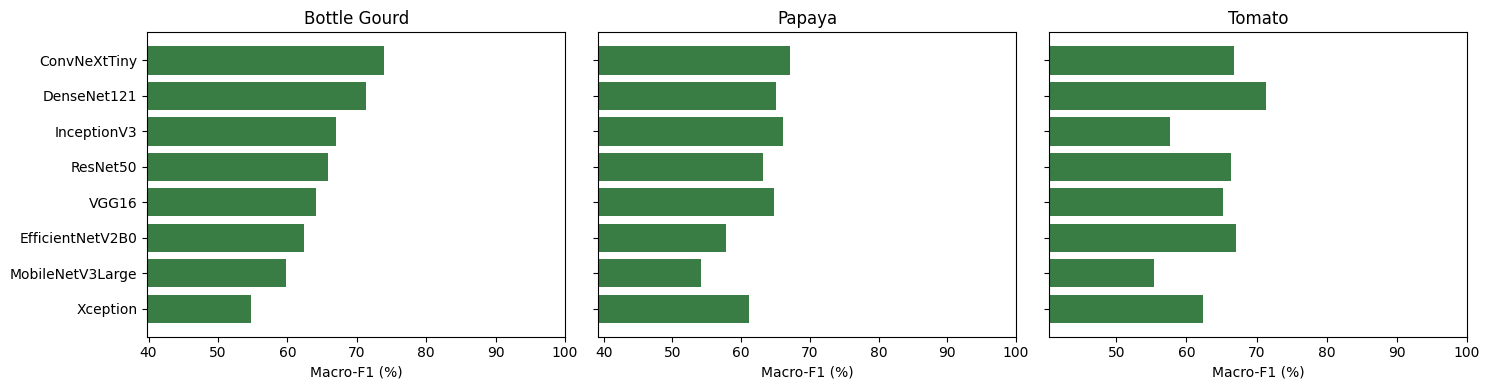

In [ ]:
import matplotlib.pyplot as plt
crops = sorted(agg.crop.unique())
fig, axes = plt.subplots(1, len(crops), figsize=(5 * len(crops), 4), sharey=True)
axes = np.atleast_1d(axes)
for ax, crop in zip(axes, crops):
    a = agg[agg.crop == crop].sort_values('macro_f1_mean')
    ax.barh(a.model, 100 * a.macro_f1_mean, xerr=100 * a.macro_f1_std.fillna(0), color='#3a7d44')
    ax.set_title(crop.replace('_', ' ')); ax.set_xlabel('Macro-F1 (%)')
    ax.set_xlim(max(0, 100 * a.macro_f1_mean.min() - 15), 100)
plt.tight_layout()
fig.savefig(PROJECT / 'figures' / 'baselines_macro_f1.pdf')
fig.savefig(PROJECT / 'figures' / 'baselines_macro_f1.png', dpi=200)
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd, numpy as np, json
from pathlib import Path
OUT = Path('/content/drive/MyDrive/thesis/experiments/baselines')
r = pd.read_csv(OUT / 'results.csv')

# A) Did the models learn the training photos? (train vs validation vs test accuracy)
rows = []
for _, x in r.iterrows():
    h = pd.read_csv(OUT / 'history' / f'{x.crop}_{x.model}_fold{x.fold}.csv')
    ft = h[h.phase == 'finetune'].reset_index(drop=True)
    b = ft.val_loss.idxmin()
    rows.append({'crop': x.crop, 'model': x.model,
                 'head_ep': x.epochs_head, 'ft_ep': x.epochs_finetune, 'best_ep': b + 1,
                 'train_acc': round(ft.accuracy[b], 3), 'val_acc': round(ft.val_accuracy[b], 3),
                 'test_acc': round(x.accuracy, 3)})
print('A) TRAINING CHECK')
print(pd.DataFrame(rows).sort_values(['crop', 'test_acc'], ascending=[True, False]).to_string(index=False))

# B) Which diseases get confused? (best model per crop)
print('\nB) CONFUSION MATRICES (rows = true disease, columns = predicted)')
for crop in sorted(r.crop.unique()):
    x = r[r.crop == crop].sort_values('macro_f1').iloc[-1]
    names = [c[len(crop) + 1:][:18] for c in x.classes.split('|')]
    cm = np.array(json.loads(x.confusion_matrix))
    t = pd.DataFrame(cm, index=names, columns=[n[:6] for n in names])
    t['recall_%'] = (100 * cm.diagonal() / cm.sum(1)).round(1)
    print(f'\n{crop} — {x.model}')
    print(t.to_string())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
A) TRAINING CHECK
        crop            model  head_ep  ft_ep  best_ep  train_acc  val_acc  test_acc
Bottle_Gourd      DenseNet121       10     21       16      0.771    0.731     0.775
Bottle_Gourd     ConvNeXtTiny       10     16       11      0.809    0.711     0.772
Bottle_Gourd         ResNet50        8     14        9      0.783    0.677     0.732
Bottle_Gourd      InceptionV3        8     19       14      0.789    0.694     0.728
Bottle_Gourd            VGG16       10     12        7      0.680    0.680     0.722
Bottle_Gourd MobileNetV3Large       10      6        1      0.362    0.677     0.689
Bottle_Gourd EfficientNetV2B0       10     30       28      0.749    0.673     0.682
Bottle_Gourd         Xception       10      6        1      0.291    0.561     0.629
      Papaya     ConvNeXtTiny       10     30       27      0.838    0.668     0.700
   